# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
from google.colab import drive
from pathlib import Path
import os
import shutil

drive.mount("/content/drive")

carpeta = Path("/content/drive/MyDrive/lecture6/challenge")

if not carpeta.is_dir():
    raise FileNotFoundError(f"No se encontró la carpeta: {carpeta}")

os.chdir(carpeta)
print("Carpeta de trabajo:", Path.cwd())

# Preparar la ubicación que exige el notebook.
archivo_original = carpeta / "data" / "wine.csv"
archivo_raw = carpeta / "data" / "raw" / "wine.csv"

archivo_raw.parent.mkdir(parents=True, exist_ok=True)

if not archivo_raw.exists():
    if archivo_original.exists():
        shutil.copy2(archivo_original, archivo_raw)
    else:
        raise FileNotFoundError(
            "Sube wine.csv a lecture6/challenge/data/raw."
        )

print("Archivo de entrada:", archivo_raw)

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/lecture6/challenge
Archivo de entrada: /content/drive/MyDrive/lecture6/challenge/data/raw/wine.csv


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [4]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)

# Por si el CSV utiliza punto y coma como separador.
if len(df.columns) == 1:
    df = pd.read_csv(DATA_PATH, sep=";")

df.columns = df.columns.str.strip()

if "target" not in df.columns:
    raise ValueError(
        "No se encontró la columna 'target'. "
        f"Columnas disponibles: {df.columns.tolist()}"
    )

if df["target"].isna().any():
    raise ValueError("Hay valores faltantes en target.")

print("Archivo cargado correctamente.")
display(df.head())

Archivo cargado correctamente.


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
print("Forma del conjunto:", df.shape)

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nValores faltantes por columna:")
display(df.isna().sum().to_frame("nulos"))

duplicados = int(df.duplicated().sum())
print("\nFilas duplicadas:", duplicados)

print("\nDistribución de target:")
distribucion = pd.DataFrame({
    "cantidad": df["target"].value_counts().sort_index(),
    "porcentaje": (
        df["target"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})
display(distribucion)

print("\nColumnas numéricas:")
print(df.select_dtypes(include="number").columns.tolist())

Forma del conjunto: (178, 14)

Tipos de datos:


,tipo
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64



Valores faltantes por columna:


,nulos
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0



Filas duplicadas: 0

Distribución de target:


,cantidad,porcentaje
target,,
0,59,33.15
1,71,39.89
2,48,26.97



Columnas numéricas:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']


**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

**Conclusión de calidad:**

El conjunto contiene **178 registros y 14 columnas**: 13 características numéricas de tipo `float64` y la variable objetivo `target`, de tipo `int64`. No se encontraron valores faltantes ni filas duplicadas, por lo que conservé todos los registros sin eliminar filas ni aplicar imputación.

La variable objetivo tiene tres clases: la clase **0** contiene **59 registros (33.15 %)**, la clase **1** contiene **71 registros (39.89 %)** y la clase **2** contiene **48 registros (26.97 %)**. Las clases tienen cantidades diferentes, aunque todas están representadas.

Realizaré una división **estratificada**, con **80 % para entrenamiento y 20 % para prueba**, utilizando `random_state=42` para que sea reproducible y conserve aproximadamente las proporciones de las clases. Después de la división, realizaré el análisis exploratorio únicamente sobre entrenamiento y reservaré el conjunto de prueba para la evaluación final.

## 2. Split train/test

In [6]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["target"]
)

print("Split estratificado creado correctamente.")

Split estratificado creado correctamente.


In [7]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

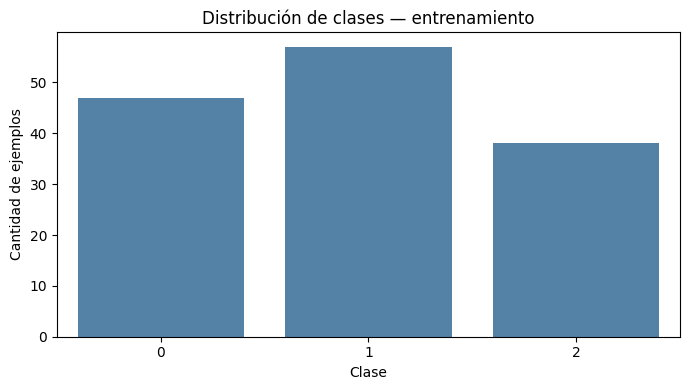

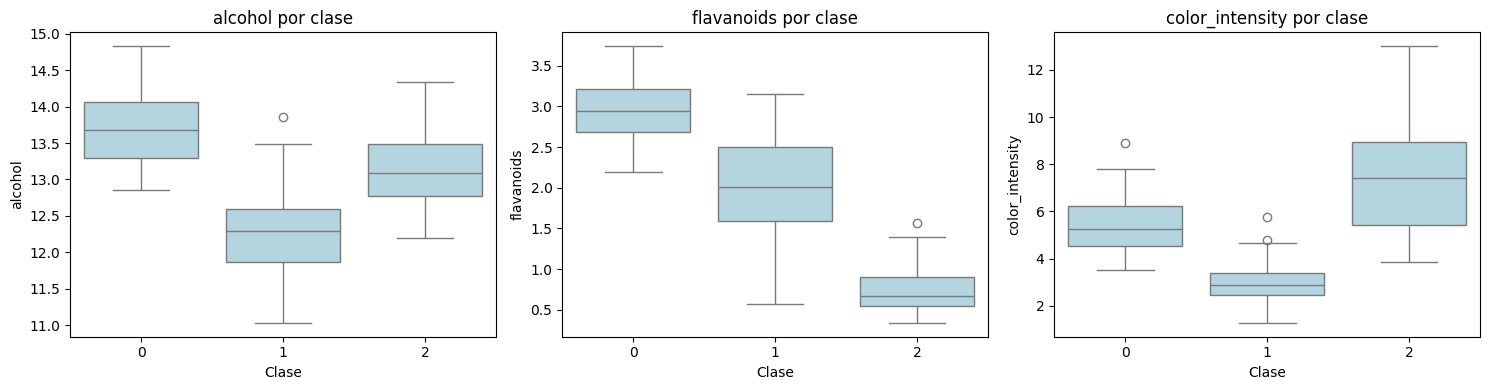

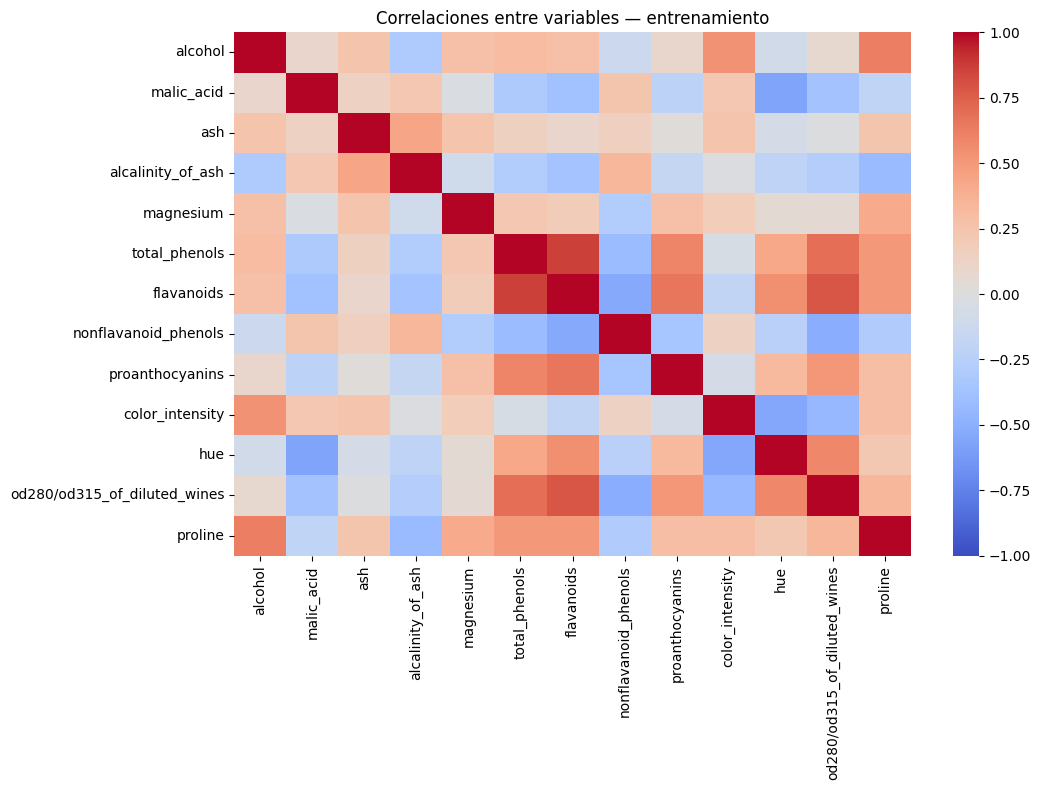

Distribución de clases en entrenamiento:


,cantidad
target,
0,47
1,57
2,38


Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
alcohol,142.0,12.971479,0.802521,11.03,12.3700,13.010,13.5600,14.83
malic_acid,142.0,2.340000,1.101285,0.74,1.6100,1.810,3.1700,5.80
ash,142.0,2.364859,0.268380,1.36,2.2000,2.360,2.5600,3.22
alcalinity_of_ash,142.0,19.625352,3.380848,10.60,17.2000,19.500,21.5000,30.00
magnesium,142.0,99.633803,14.937448,70.00,88.0000,97.000,107.7500,162.00
total_phenols,142.0,2.273732,0.621454,0.98,1.7050,2.335,2.8000,3.88
flavanoids,142.0,1.985352,0.951952,0.34,1.2275,2.135,2.7750,3.74
nonflavanoid_phenols,142.0,0.360141,0.119211,0.13,0.2700,0.340,0.4300,0.63
proanthocyanins,142.0,1.600211,0.579777,0.42,1.2500,1.560,1.9500,3.58
color_intensity,142.0,4.989648,2.334947,1.28,3.0575,4.640,6.1825,13.00


Medianas de las variables seleccionadas por clase:


,alcohol,flavanoids,color_intensity
target,,,
0,13.680,2.940,5.25
1,12.290,2.010,2.90
2,13.095,0.675,7.40


Pares con mayor correlación absoluta:


,,correlacion
total_phenols,flavanoids,0.860927
flavanoids,od280/od315_of_diluted_wines,0.786320
total_phenols,od280/od315_of_diluted_wines,0.694710
flavanoids,proanthocyanins,0.657046
alcohol,proline,0.620742


In [8]:
features = [col for col in train_df.columns if col != "target"]

numeric_features = (
    train_df[features]
    .select_dtypes(include="number")
    .columns.tolist()
)

if not numeric_features:
    raise ValueError("No se encontraron variables numéricas para el EDA.")

# 1. Distribución de clases.
fig, ax = plt.subplots()

sns.countplot(
    data=train_df,
    x="target",
    color="steelblue",
    ax=ax
)

ax.set_title("Distribución de clases — entrenamiento")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad de ejemplos")

fig.tight_layout()
fig.savefig(REPORTS_DIR / "01_distribucion_clases.png", dpi=150)
plt.show()

# Seleccionar variables conocidas si existen.
preferidas = ["alcohol", "flavanoids", "color_intensity"]

selected_features = [
    col for col in preferidas if col in numeric_features
]

for col in numeric_features:
    if len(selected_features) >= 3:
        break
    if col not in selected_features:
        selected_features.append(col)

# 2. Boxplots de variables por clase.
fig, axes = plt.subplots(
    1,
    len(selected_features),
    figsize=(5 * len(selected_features), 4),
    squeeze=False
)

for ax, feature in zip(axes[0], selected_features):
    sns.boxplot(
        data=train_df,
        x="target",
        y=feature,
        color="lightblue",
        ax=ax
    )
    ax.set_title(f"{feature} por clase")
    ax.set_xlabel("Clase")

fig.tight_layout()
fig.savefig(REPORTS_DIR / "02_boxplots_por_clase.png", dpi=150)
plt.show()

# 3. Correlaciones entre características numéricas.
correlaciones = train_df[numeric_features].corr()

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlaciones,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlaciones entre variables — entrenamiento")

fig.tight_layout()
fig.savefig(REPORTS_DIR / "03_correlaciones.png", dpi=150)
plt.show()

# Información de apoyo para redactar los hallazgos.
print("Distribución de clases en entrenamiento:")
display(
    train_df["target"]
    .value_counts()
    .sort_index()
    .to_frame("cantidad")
)

print("Resumen de variables numéricas:")
display(train_df[numeric_features].describe().T)

print("Medianas de las variables seleccionadas por clase:")
display(
    train_df.groupby("target")[selected_features].median()
)

# Pares de variables con mayor correlación absoluta.
mascara = np.triu(
    np.ones(correlaciones.shape, dtype=bool),
    k=1
)

pares = correlaciones.where(mascara).stack()

if not pares.empty:
    orden = pares.abs().sort_values(ascending=False).index

    print("Pares con mayor correlación absoluta:")
    display(
        pares.loc[orden].head(5).to_frame("correlacion")
    )

**Hallazgos:**

1. **Distribución de clases:** el conjunto de entrenamiento contiene **142 registros**: 47 de la clase 0, 57 de la clase 1 y 38 de la clase 2. La clase 1 es la más frecuente y la clase 2 es la menos frecuente. Como las cantidades son diferentes, compararé los modelos mediante **F1 macro** y revisaré las métricas por clase, para evitar que el rendimiento sobre la clase mayoritaria oculte dificultades al clasificar las demás.

2. **Variables que pueden ayudar a distinguir las clases:** las medianas de flavanoids son **2.940**, **2.010** y **0.675** para las clases 0, 1 y 2, respectivamente. En color_intensity, las medianas son **5.25**, **2.90** y **7.40**. Además, la clase 1 presenta la menor mediana de alcohol: **12.290**. Estas diferencias sugieren que las tres variables pueden aportar información útil para la clasificación, aunque no garantizan una separación perfecta. También hay diferencias importantes de escala entre las características, por lo que consideraré estandarizarlas si el modelo lo requiere, ajustando el escalador únicamente con los datos de entrenamiento.

3. **Correlaciones entre características:** total_phenols y flavanoids presentan una correlación positiva fuerte de aproximadamente **0.861**. También existe una correlación de **0.786** entre flavanoids y od280/od315_of_diluted_wines. Esto indica que algunas variables pueden aportar información parcialmente compartida. No eliminaré características únicamente por su correlación; evaluaré mediante validación sobre entrenamiento si la selección de variables o la regularización mejora el modelo, sin utilizar el conjunto de prueba para tomar estas decisiones.

## 4. Persistencia de datos y contrato

In [9]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_path = PROCESSED_DATA_DIR / "train.csv"
test_path = PROCESSED_DATA_DIR / "test.csv"
contract_path = ARTIFACTS_DIR / "data_contract.json"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

data_contract = {
    "target": "target",
    "features": [
        col for col in train_df.columns if col != "target"
    ],
    "random_state": int(RANDOM_STATE),
    "test_size": 0.20
}

with contract_path.open("w", encoding="utf-8") as archivo:
    json.dump(
        data_contract,
        archivo,
        indent=2,
        ensure_ascii=False
    )

print("Archivos guardados:")
print(train_path)
print(test_path)
print(contract_path)

Archivos guardados:
/content/drive/MyDrive/lecture6/challenge/data/processed/train.csv
/content/drive/MyDrive/lecture6/challenge/data/processed/test.csv
/content/drive/MyDrive/lecture6/challenge/artifacts/data_contract.json


In [10]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test después del split.
- [x] Guardé los tres artefactos requeridos.